# Filbin et al. 2018 — H3-K27M Glioma
## 06 · EMT-TF expression (unconditional final step)

Overlay the most informative EMT transcription factors on the manifold. Panel scored by detection
(>=15% expressers) and arm-specificity; VIM is excluded (a mesenchymal marker, not a TF). Shown as a
**categorical thresholded-expresser overlay** on a grey manifold (reference style), one colour per TF.

In [ ]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # e.g. Filbin2018_Brain-9  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Brain)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir] * 6))                 # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Filbin2018_Brain-9 | category: Brain


### Load the manifold (with trajectory + arms) and the candidate TF panel

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
panel = ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
panel = [g for g in panel if g in adata.var_names]
# arms from tree segments: AC-like arm vs OC-like arm (by dominant celltype per segment)
seg_ct = adata.obs.groupby('seg', observed=True)['celltype'].agg(lambda s: s.value_counts().index[0])
X = adata[:, panel].X.toarray()
rows = []
for i, gname in enumerate(panel):
    x = X[:, i]; frac = (x > 0).mean()
    ac = x[(adata.obs.celltype == 'AC-like').values].mean()
    oc = x[(adata.obs.celltype == 'OC-like').values].mean()
    rows.append(dict(gene=gname, frac=round(frac, 2), AC_mean=round(ac, 2), OC_mean=round(oc, 2)))
tf = pd.DataFrame(rows).sort_values('frac', ascending=False)
print(tf.to_string(index=False))

  gene  frac  AC_mean  OC_mean
  ZEB1  0.77     2.74     3.81
  ZEB2  0.76     2.40     3.40
 PRRX1  0.56     2.65     2.17
 SNAI1  0.08     0.32     0.28
 SNAI2  0.03     0.21     0.10
 FOXC2  0.01     0.01     0.01
 PRRX2  0.01     0.03     0.06
TWIST1  0.00     0.00     0.01
TWIST2  0.00     0.00     0.00
 FOXC1  0.00     0.01     0.00


### Select arm-specific TFs (detection-gated)
Keep TFs expressed in >=15% of cells; pick the pair that best separates the two arms. ZEB1/ZEB2/PRRX1
are the robust detectable program; **PRRX1 (AC-arm)** and **ZEB2 (OC-arm)** are the arm-specific pair.

In [ ]:
det = tf[tf.frac >= 0.15].copy()
print('detectable TFs (>=15%):', det.gene.tolist())
# arm bias
det['AC_bias'] = det.AC_mean - det.OC_mean
ac_tf = det.sort_values('AC_bias', ascending=False).gene.iloc[0]
oc_tf = det.sort_values('AC_bias', ascending=True).gene.iloc[0]
print('AC-arm TF:', ac_tf, '| OC-arm TF:', oc_tf)

detectable TFs (>=15%): ['ZEB1', 'ZEB2', 'PRRX1']
AC-arm TF: PRRX1 | OC-arm TF: ZEB1


### `expression.pdf` — EMT-TF overlay (categorical, thresholded expressers)

saved expression.pdf | AC-arm PRRX1 / OC-arm ZEB1


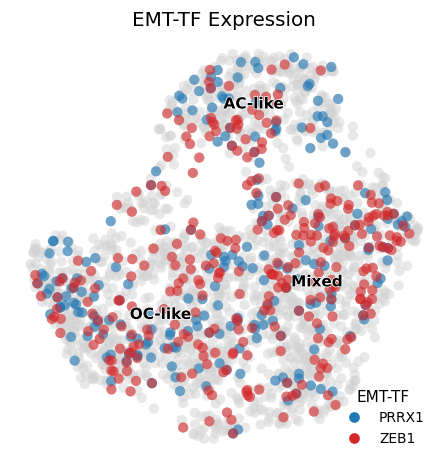

In [ ]:
# thresholds: label a cell an "expresser" above a per-gene positive-expression cutoff
def thr(gene, q=0.80):
    x = adata[:, gene].X.toarray().ravel(); pos = x[x > 0]
    return np.quantile(pos, q) if pos.size else np.inf
g_plt = {ac_tf: ('tab:blue', thr(ac_tf)), oc_tf: ('tab:red', thr(oc_tf))}
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=180, alpha=.5, frameon=False, show=False, ax=ax)
for var, (c, t) in g_plt.items():
    sub = adata[adata[:, var].X.toarray().ravel() > t].copy()
    sc.pl.umap(sub, na_color=c, size=180, alpha=.6, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=8, label=v)
           for v, (c, t) in g_plt.items()]
ax.legend(handles=handles, loc='lower right', frameon=False, fontsize=9, title='EMT-TF')
ax.set_title('EMT-TF Expression', size=13)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight'); plt.show()
print('saved expression.pdf | AC-arm', ac_tf, '/ OC-arm', oc_tf)